<a href="https://colab.research.google.com/github/Gagandeep1227/ML-2/blob/main/SOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
pip install minisom numpy pandas matplotlib scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=228107f434761728ef96c142e4636b593b38ffb6d4967d2b0ff9b474e3264b25
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

SOM Training Completed Successfully!


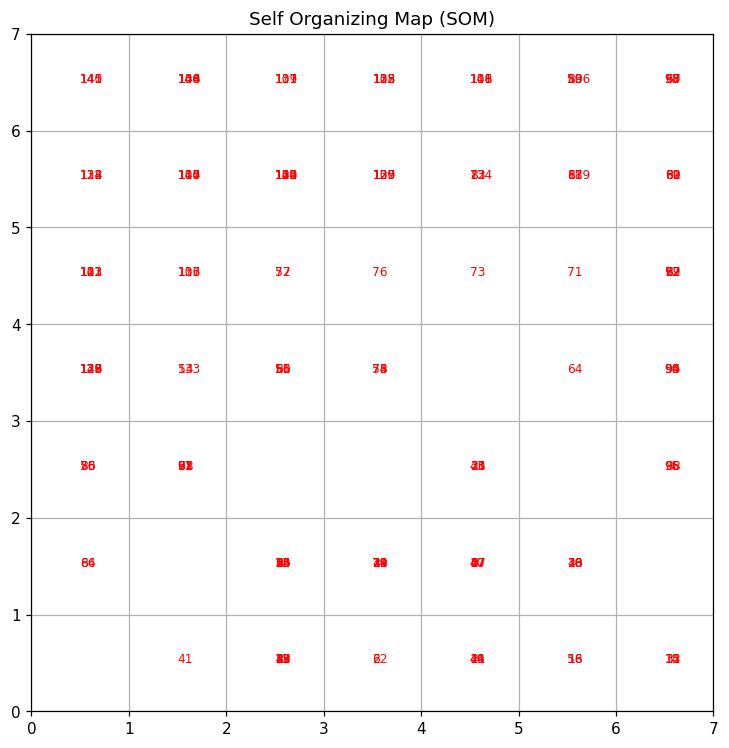

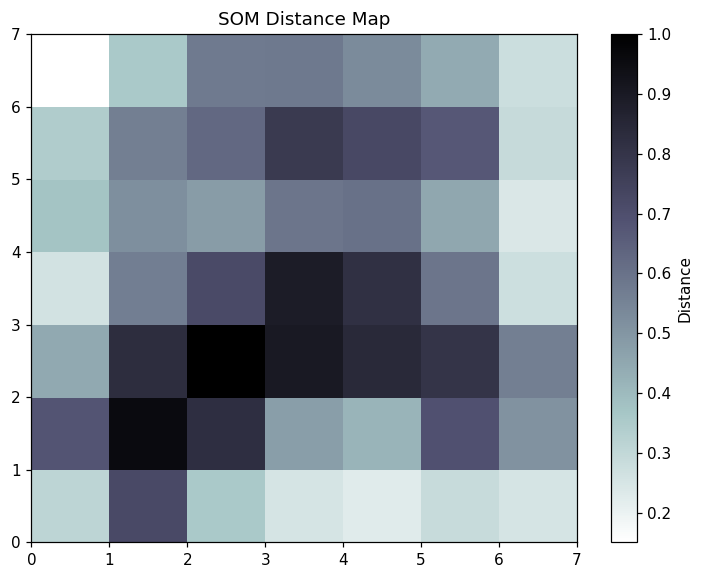

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("Dataset:")
print(df.head())

scaler = MinMaxScaler()
data = scaler.fit_transform(df)

som = MiniSom(
    x=7,
    y=7,
    input_len=data.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

som.random_weights_init(data)

som.train_random(data, num_iteration=1000)

print("\nSOM Training Completed Successfully!")

plt.figure(figsize=(8, 8))

for i, x in enumerate(data):
    w = som.winner(x)

    plt.text(
        w[0] + 0.5,
        w[1] + 0.5,
        str(i),
        color='red',
        fontsize=8
    )

plt.title("Self Organizing Map (SOM)")
plt.xlim([0, 7])
plt.ylim([0, 7])
plt.grid()
plt.show()

plt.figure(figsize=(8, 6))

plt.pcolor(
    som.distance_map().T,
    cmap='bone_r'
)

plt.colorbar(label="Distance")

plt.title("SOM Distance Map")
plt.show()

Loading dataset...

Dataset Loaded Successfully!
Dataset Shape: (20640, 10)

First 5 Rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  Class  
0    -122.23        4.526      0  
1    -122.22        3.585      0  
2    -122.24        3.521      0  
3    -122.25        3.413      0  
4    -122.25        3.422      0  

Training samples: 5000

Training SOM...
 [ 5000 / 5000 ] 100% - 0:00:00 left 
 quantization error: 0.7682688511135182

SOM Training Completed!

Anomaly Detection Results
Threshold: 1.3487
Transactions Evaluated: 10000
Unusual Transactions: 5

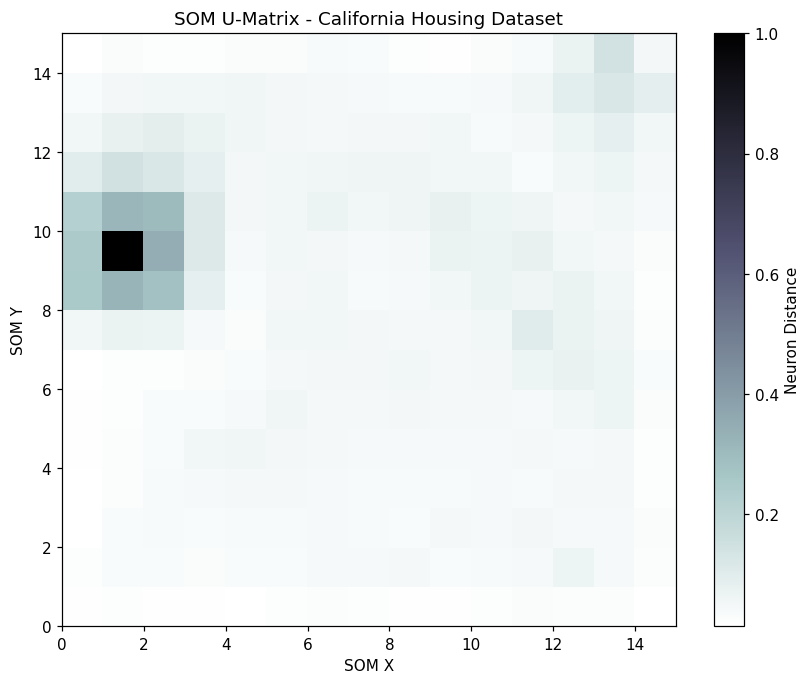

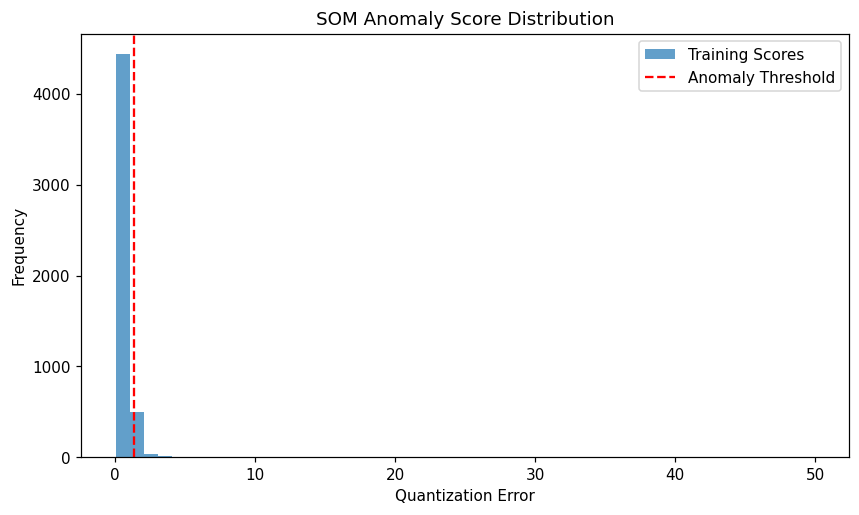


Sample Results:
   Actual_Class  Anomaly_Score  Predicted_Anomaly
0             0       0.511501              False
1             0       0.708208              False
2             0       0.619022              False
3             0       0.641394              False
4             0       0.453417              False
5             0       0.595058              False
6             0       1.246586              False
7             0       0.656814              False
8             0       0.642877              False
9             0       0.500651              False

Results saved to som_results.csv

PROGRAM EXECUTED SUCCESSFULLY!


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_california_housing

print("Loading dataset...")

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

price_threshold = df["MedHouseVal"].quantile(0.98)
df["Class"] = (df["MedHouseVal"] > price_threshold).astype(int)

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

X = df.drop(columns=["Class"])
y = df["Class"]

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rng = np.random.default_rng(42)

train_size = min(5000, len(X_scaled))
train_indices = rng.choice(
    len(X_scaled),
    size=train_size,
    replace=False
)

X_train = X_scaled[train_indices]

print("\nTraining samples:", len(X_train))

som = MiniSom(
    x=15,
    y=15,
    input_len=X_train.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

som.random_weights_init(X_train)

print("\nTraining SOM...")

som.train_random(
    X_train,
    num_iteration=5000,
    verbose=True
)

print("\nSOM Training Completed!")

train_quantized = som.quantization(X_train)

train_scores = np.linalg.norm(
    X_train - train_quantized,
    axis=1
)

threshold = np.percentile(train_scores, 95)

eval_size = min(10000, len(X_scaled))

eval_indices = rng.choice(
    len(X_scaled),
    size=eval_size,
    replace=False
)

X_eval = X_scaled[eval_indices]
y_eval = y.iloc[eval_indices].to_numpy()

eval_quantized = som.quantization(X_eval)

anomaly_scores = np.linalg.norm(
    X_eval - eval_quantized,
    axis=1
)

predictions = anomaly_scores > threshold

print("\nAnomaly Detection Results")
print("Threshold:", round(threshold, 4))
print("Transactions Evaluated:", eval_size)
print("Unusual Transactions:", predictions.sum())

actual_fraud = y_eval == 1

print("\nActual Fraud Transactions:", actual_fraud.sum())

if actual_fraud.sum() > 0:
    detected_fraud = np.sum(predictions & actual_fraud)
    print("Fraud Transactions Flagged:", detected_fraud)

plt.figure(figsize=(9, 7))

plt.pcolor(
    som.distance_map().T,
    cmap="bone_r"
)

plt.colorbar(label="Neuron Distance")
plt.title("SOM U-Matrix - California Housing Dataset")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()

plt.figure(figsize=(9, 5))

plt.hist(
    train_scores,
    bins=50,
    alpha=0.7,
    label="Training Scores"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.title("SOM Anomaly Score Distribution")
plt.xlabel("Quantization Error")
plt.ylabel("Frequency")
plt.legend()

plt.show()

results = pd.DataFrame({
    "Actual_Class": y_eval,
    "Anomaly_Score": anomaly_scores,
    "Predicted_Anomaly": predictions
})

print("\nSample Results:")
print(results.head(10))

results.to_csv("som_results.csv", index=False)

print("\nResults saved to som_results.csv")
print("\nPROGRAM EXECUTED SUCCESSFULLY!")